In [8]:
import pandas as pd

# Load real-world Telco Customer Churn dataset from URL
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Display the dataset size and the first 5 rows
print(f"Dataset Loaded Successfully! Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
df.head()

Dataset Loaded Successfully! Total Rows: 7043, Total Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Convert TotalCharges to numeric, setting invalid blank strings to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Fill missing TotalCharges with 0 (since tenure is 0 for these customers)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify no missing values remain
print("Missing values per column after cleaning:")
print(df[['TotalCharges', 'MonthlyCharges', 'tenure']].isnull().sum())

Missing values per column after cleaning:
TotalCharges      0
MonthlyCharges    0
tenure            0
dtype: int64


/tmp/ipykernel_1805/538678482.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2', ax=axes[0])


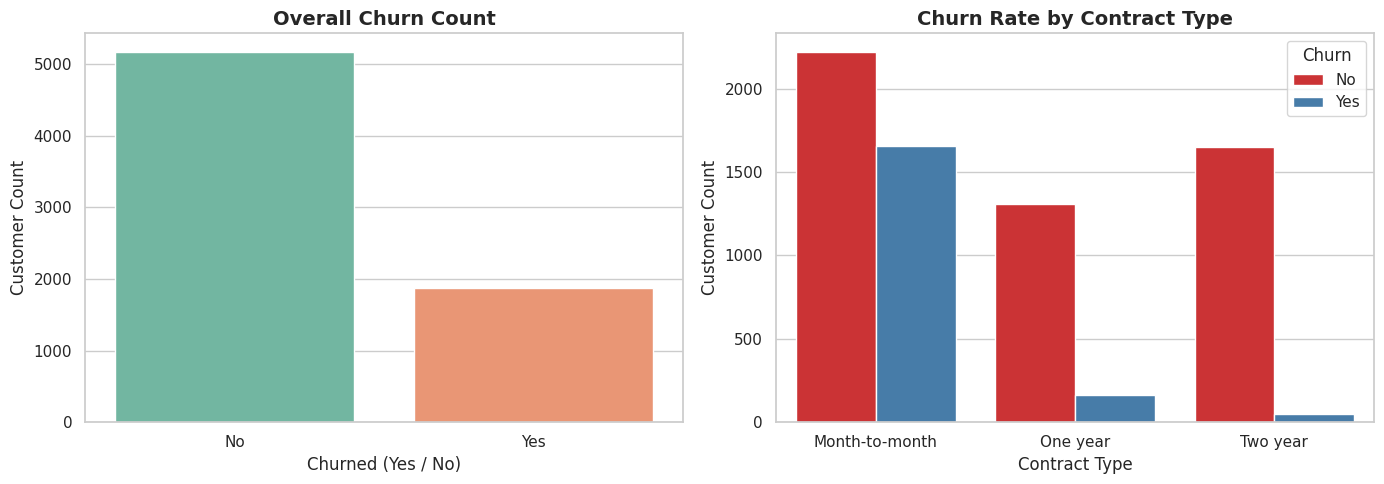

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Churn Count Distribution
sns.countplot(data=df, x='Churn', palette='Set2', ax=axes[0])
axes[0].set_title('Overall Churn Count', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Churned (Yes / No)')
axes[0].set_ylabel('Customer Count')

# Chart 2: Churn Rate by Contract Type
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1', ax=axes[1])
axes[1].set_title('Churn Rate by Contract Type', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Contract Type')
axes[1].set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Drop identifier column and encode target variable (Yes=1, No=0)
df_model = df.drop(columns=['customerID']).copy()
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

# 2. One-Hot Encode remaining categorical features
df_encoded = pd.get_dummies(df_model, drop_first=True)

# 3. Separate Features (X) and Target (y)
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# 4. Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Scale numeric features (tenure, MonthlyCharges, TotalCharges)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training shape: {X_train.shape}, Testing shape: {X_test.shape}")

Training shape: (5634, 30), Testing shape: (1409, 30)


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Initialize models
log_reg = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train models
log_reg.fit(X_train_scaled, y_train)
rf_model.fit(X_train, y_train)

# Predict on testing set
y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)

# Compare Results
print("=== Logistic Regression Performance ===")
print(classification_report(y_test, y_pred_lr, target_names=['No Churn', 'Churn']))

print("\n=== Random Forest Performance ===")
print(classification_report(y_test, y_pred_rf, target_names=['No Churn', 'Churn']))


=== Logistic Regression Performance ===
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


=== Random Forest Performance ===
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.62      0.50      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409



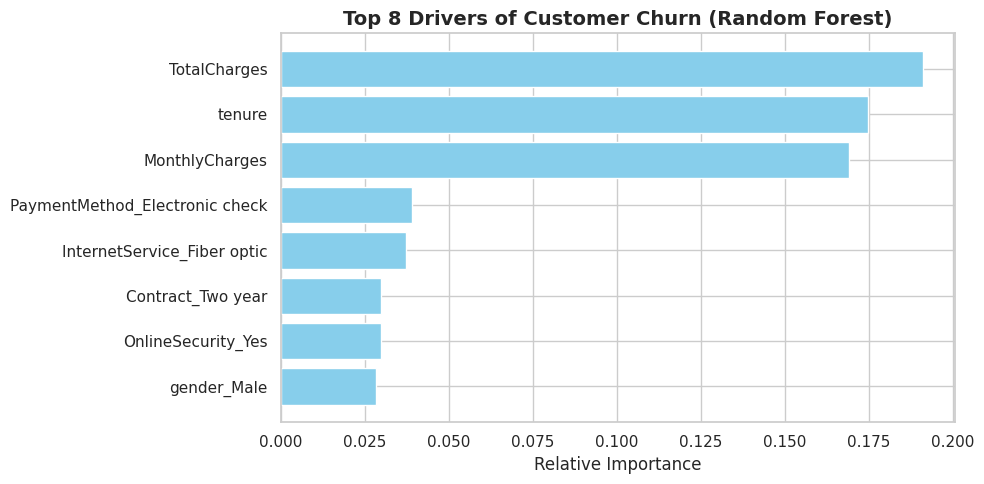

In [6]:
import numpy as np

# Extract feature importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[-8:]  # Top 8 features

plt.figure(figsize=(10, 5))
plt.barh(range(len(indices)), importances[indices], color='skyblue')
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.title('Top 8 Drivers of Customer Churn (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()